# Notebook 05: Advanced methods check

Notebooks 01 to 04 found that simple models (Ridge, Random Forest), rules and optimization work best. This notebook asks: **would more advanced methods do better?** Each method below is **tested on the data**, not just argued:

| # | Method | Idea from the project brief | Tested on |
|---|---|---|---|
| 1 | **Spatial / graph models** (kriging, GNN-style neighbour aggregation) | "Trim codes correlate across the wafer" | MCU, PMIC, sensor, SoC |
| 2 | **Confidence-based fallback** (quantile regression) | "Fall back to the conventional search when confidence is low" | MCU HSI, SoC binning, sensor |
| 3 | **Transfer learning with fine-tuning** | "Fine-tune per derivative with a small set of dies" | MCU-C packaging drift |
| 4 | GAN, RNN/LSTM, reinforcement learning | reviewed with reasons | — |

The last part sums up every method across all notebooks: what was tested, whether it helped, and what to use.

**Colab:** Runtime → Run all, and upload the dataset zip when asked (4 CSVs are needed).

## 0.1 Setup

In [1]:
import importlib, subprocess, sys
for pkg in ["lightgbm"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
SEED = 42
print("Libraries loaded")

Libraries loaded


## 0.2 Load the four modelling datasets

In [2]:
NEEDED = ["mcu_trim_fuse.csv", "pmic_trim_otp.csv", "sensor_calibration.csv", "soc_binning_harvesting.csv",
          "soc_sku_demand.csv"]

def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None

if any(find(f) is None for f in NEEDED):
    try:
        from google.colab import files
        print("Upload the dataset zip or:", NEEDED)
        for fname in files.upload():
            if fname.lower().endswith(".zip"):
                zipfile.ZipFile(fname).extractall("dataset_upload")
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook")

mcu, pmic, sensor, soc, sku = (pd.read_csv(find(f)) for f in NEEDED)
print({n: d.shape for n, d in zip(["mcu", "pmic", "sensor", "soc", "sku"], [mcu, pmic, sensor, soc, sku])})

{'mcu': (8420, 42), 'pmic': (11060, 63), 'sensor': (11060, 67), 'soc': (6160, 52), 'sku': (3, 6)}


## 0.3 Rebuild the final model setups from notebooks 01 to 04
The same features, splits (by wafer, seed 42) and final model families, so the comparisons start from the real results:

| Task | Final model | Target |
|---|---|---|
| MCU bandgap | Random Forest | `bg_trim_code_opt` |
| MCU HSI (hardest trim) | Random Forest | `hsi_trim_code_opt` |
| PMIC buck1, from the reference only | Ridge | `buck1_trim_code_opt` |
| Sensor X-axis TCO, from 25 °C | Ridge | `tco_x_true_mg_per_C` |
| SoC 6th-fastest core | Ridge | `f_top6` (GHz) |

In [3]:
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]

def wafer_split(df):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(df, groups=df.wafer_id))
    return df.iloc[tr].reset_index(drop=True), df.iloc[te].reset_index(drop=True)

rf = lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0))

# MCU (notebook 01 features + physics features)
mcuA = mcu[mcu.derivative == "MCU-A"].reset_index(drop=True)
mcuA["bg_ideal"] = 32 - (mcuA.bg_untrim_V - 1.2) / 0.002
mcuA["hsi_ideal"] = 64 + (16 / mcuA.hsi_untrim_MHz - 1) / 0.002
# PMIC (notebook 02)
p1 = pmic[pmic.derivative == "PMIC-P1"].reset_index(drop=True)
p1["ref_ideal_code"] = 32 + (0.6 / p1.vref_trimmed_sort_V - 1) / 0.002
p1["vref_err_mV"] = (p1.vref_untrim_V - 0.6) * 1000
# Sensor (notebook 03, X axis, die level)
s2 = sensor[sensor.derivative == "ACC-2G"].reset_index(drop=True)
s2["offset_25C_mean3"] = s2[[f"offset_{a}_25C_mg" for a in "xyz"]].mean(axis=1)
s2["sens_25C_mean3"] = s2[[f"sens_{a}_25C_rel" for a in "xyz"]].mean(axis=1)
# SoC (notebook 04)
FC = [f"core{i}_fmax_GHz" for i in range(8)]
soc["n_good_cores"] = soc[FC].notna().sum(axis=1)
soc["leak_hot_A"] = soc.iddq_25C_mA * 22 / 1000
fs = -np.sort(-soc[FC].fillna(-1).values, axis=1)
for k in (8, 6, 4):
    soc[f"f_top{k}"] = np.where(fs[:, k - 1] > 0, fs[:, k - 1], np.nan)
soc["ro_x_cpm"] = soc.ro_freq_MHz / soc.cpm_path_delay_ps
soc["log_iddq"] = np.log(soc.iddq_25C_mA)

TASKS = [
    dict(name="MCU bandgap code", data=mcuA, target="bg_trim_code_opt", model=rf, bits=6,
         feats=["bg_untrim_V", "bg_ideal"] + PCM + POS),
    dict(name="MCU HSI code", data=mcuA, target="hsi_trim_code_opt", model=rf, bits=7,
         feats=["hsi_untrim_MHz", "hsi_ideal", "bg_trimmed_sort_V"] + PCM + POS),
    dict(name="PMIC buck1 code (ref only)", data=p1, target="buck1_trim_code_opt", model=ridge, bits=6,
         feats=["vref_untrim_V", "vref_trimmed_sort_V", "ref_ideal_code", "vref_err_mV"] + PCM + POS),
    dict(name="Sensor TCO X", data=s2, target="tco_x_true_mg_per_C", model=ridge, bits=None,
         feats=["offset_x_25C_mg", "sens_x_25C_rel", "st_response_x_mg", "stress_gauge_mV", "asic_vref_mV",
                "mems_resonance_kHz", "mems_q_factor", "offset_25C_mean3", "sens_25C_mean3"] + PCM + POS),
    dict(name="SoC 6th-fastest core", data=soc[soc.f_top6.notna()].reset_index(drop=True), target="f_top6",
         model=ridge, bits=None, feats=["ro_freq_MHz", "cpm_path_delay_ps", "iddq_25C_mA", "n_good_cores",
                                        "ro_x_cpm", "log_iddq"] + PCM + POS),
]

def split_task(t):
    tr, te = wafer_split(t["data"])
    if t["name"].startswith("Sensor"):          # train on characterized dies, test on production dies
        tr, te = tr[tr.characterized_3temp].reset_index(drop=True), te[~te.characterized_3temp].reset_index(drop=True)
    return tr, te

def score(t, y, p):
    out = {"MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}
    if t["bits"]:
        c = np.clip(np.round(p), 0, 2 ** t["bits"] - 1)
        out["within1_%"] = (np.abs(c - y) <= 1).mean() * 100
    return out

base = {}
for t in TASKS:
    tr, te = split_task(t)
    m = t["model"]().fit(tr[t["feats"]], tr[t["target"]])
    te = te.assign(pred=m.predict(te[t["feats"]]))
    te["resid"] = te[t["target"]] - te.pred
    base[t["name"]] = dict(train=tr, test=te, model=m)
    print(f"{t['name']:28s}", {k: round(v, 4) for k, v in score(t, te[t["target"]], te.pred).items()})

MCU bandgap code             {'MAE': 0.2558, 'R2': 0.9944, 'within1_%': np.float64(99.8812)}


MCU HSI code                 {'MAE': 0.6913, 'R2': 0.9973, 'within1_%': np.float64(82.7197)}
PMIC buck1 code (ref only)   {'MAE': 0.6442, 'R2': 0.9314, 'within1_%': np.float64(93.7613)}
Sensor TCO X                 {'MAE': 0.0517, 'R2': 0.8086}
SoC 6th-fastest core         {'MAE': 0.02, 'R2': 0.9909}


# Part 1: Spatial and graph models

**The key question:** after the model has used each die's own measurements, are its **errors** related to its neighbours' errors?
- **If yes:** neighbouring dies carry extra information, and spatial models (kriging, CNN wafer maps, graph neural networks) can help.
- **If no:** the leftover error is random from die to die, and **no spatial or graph model can reduce it**, however complex.

## 1.1 Neighbour helper
Each die's 8 surrounding dies on the same wafer (from `die_x`, `die_y`). This is the "graph" a GNN would use: dies are nodes, and neighbours are linked.

In [4]:
def neighbour_mean(df, cols):
    # Mean of `cols` over each die's 8 neighbours on the same wafer (NaN if none present)
    keys = ["wafer_id", "die_x", "die_y"]
    left = df[keys].reset_index()
    sums = np.zeros((len(df), len(cols))); counts = np.zeros(len(df))
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            if dx == dy == 0:
                continue
            sh = df[keys + cols].copy(); sh["die_x"] -= dx; sh["die_y"] -= dy
            v = left.merge(sh, on=keys, how="left").sort_values("index")[cols].values
            ok = ~np.isnan(v[:, 0]); sums[ok] += v[ok]; counts += ok
    with np.errstate(invalid="ignore"):
        return pd.DataFrame(sums / counts[:, None], index=df.index, columns=cols)
print("Neighbour helper ready")

Neighbour helper ready


## 1.2 Test 1: are the errors spatially correlated?
Two measures per task:
- **Neighbour correlation:** the correlation between each die's error and its neighbours' average error. Near 0 means random.
- **Wafer share:** the share of error variance explained by which wafer a die is on. Near 0 means no wafer-level offset is left to learn.

In [5]:
rows = []
for t in TASKS:
    te = base[t["name"]]["test"]
    nb = neighbour_mean(te, ["resid"])["resid"]
    ok = nb.notna()
    wafer_share = te.groupby("wafer_id").resid.transform("mean").var() / te.resid.var()
    rows.append({"task": t["name"], "dies_with_neighbours": int(ok.sum()),
                 "neighbour_corr": np.corrcoef(te.resid[ok], nb[ok])[0, 1], "wafer_share_%": wafer_share * 100})
spatial = pd.DataFrame(rows)
print(spatial.round(3).to_string(index=False))

                      task  dies_with_neighbours  neighbour_corr  wafer_share_%
          MCU bandgap code                  1684           0.038          1.272
              MCU HSI code                  1684          -0.017          0.031
PMIC buck1 code (ref only)                  2212           0.001          0.767
              Sensor TCO X                  1790           0.092          0.720
      SoC 6th-fastest core                  1439           0.065          1.001


## 1.3 Picture: error map of one test wafer per task
If there were a spatial pattern, these maps would show blobs, rings or gradients. Random speckle means no pattern.

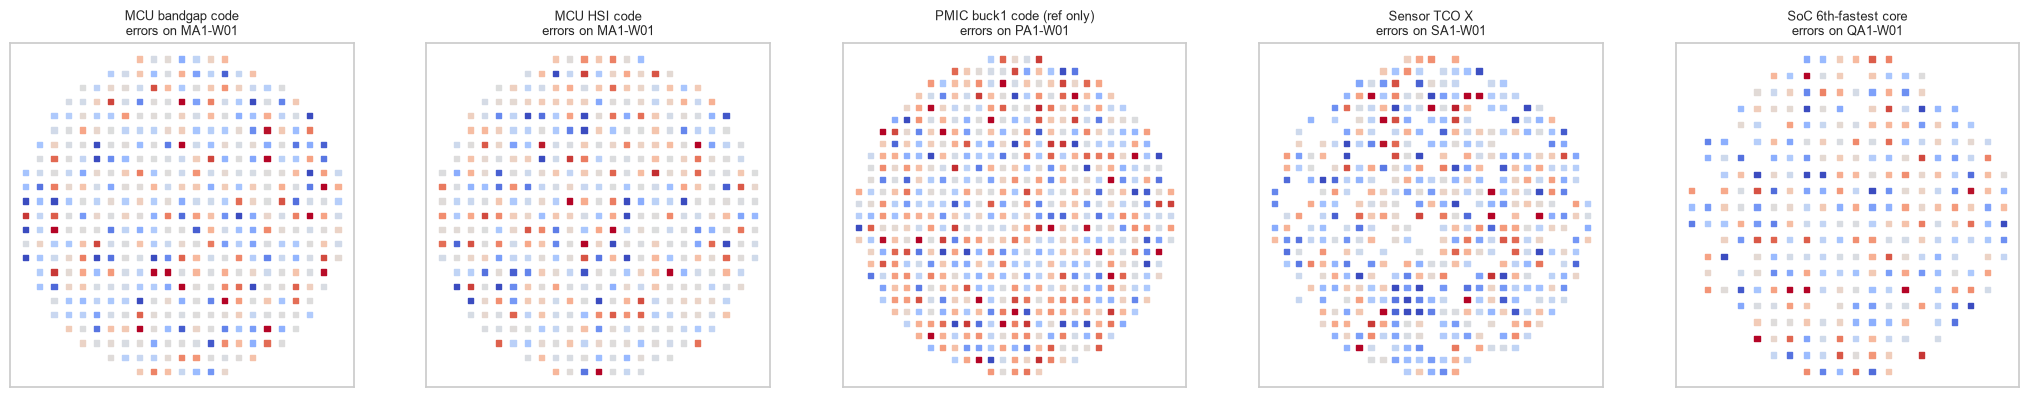

In [6]:
fig, ax = plt.subplots(1, len(TASKS), figsize=(4.2 * len(TASKS), 4))
for a, t in zip(ax, TASKS):
    te = base[t["name"]]["test"]; w = te.wafer_id.iloc[0]; one = te[te.wafer_id == w]
    lim = np.abs(te.resid).quantile(0.95)
    sc = a.scatter(one.x_mm, one.y_mm, c=one.resid, cmap="coolwarm", vmin=-lim, vmax=lim, s=14, marker="s")
    a.set_title(f"{t['name']}\nerrors on {w}", fontsize=9); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 1.4 Test 2: kriging-style correction from a sparse sample
This is the brief's wafer-map idea: on each test wafer, **10% of dies get the full measurement**, so their true values, and therefore their errors, are known. For every other die, we add the inverse-distance-weighted average error of its 4 nearest measured dies. This is the core of kriging.

If the errors are spatially random, the correction adds noise and does not help.

In [7]:
def kriging_correct(te, frac=0.10, k=4):
    rng = np.random.default_rng(SEED)
    corr = pd.Series(np.nan, index=te.index); known = pd.Series(False, index=te.index)
    for w, g in te.groupby("wafer_id"):
        kn = rng.random(len(g)) < frac
        known.loc[g.index[kn]] = True
        K, U = g[kn], g[~kn]
        d = np.hypot(U.x_mm.values[:, None] - K.x_mm.values[None], U.y_mm.values[:, None] - K.y_mm.values[None])
        idx = np.argsort(d, axis=1)[:, :k]
        wts = 1 / (np.take_along_axis(d, idx, 1) + 1e-6)
        corr.loc[U.index] = (K.resid.values[idx] * wts).sum(1) / wts.sum(1)
    return corr, known

rows = []
for t in TASKS:
    te = base[t["name"]]["test"]
    corr, known = kriging_correct(te)
    u = te[~known]
    b = score(t, u[t["target"]], u.pred); kr = score(t, u[t["target"]], u.pred + corr[~known])
    rows.append({"task": t["name"], "MAE_model": b["MAE"], "MAE_+kriging": kr["MAE"],
                 "change_%": (kr["MAE"] / b["MAE"] - 1) * 100,
                 **({"within1_model": b["within1_%"], "within1_+kriging": kr["within1_%"]} if t["bits"] else {})})
krig = pd.DataFrame(rows)
print(krig.round(3).to_string(index=False))

                      task  MAE_model  MAE_+kriging  change_%  within1_model  within1_+kriging
          MCU bandgap code      0.257         0.331    28.654         99.935            99.673
              MCU HSI code      0.687         0.921    34.008         82.799            79.595
PMIC buck1 code (ref only)      0.644         0.723    12.151         93.610            89.965
              Sensor TCO X      0.052         0.058    12.277            NaN               NaN
      SoC 6th-fastest core      0.020         0.023    12.760            NaN               NaN


## 1.5 Test 3: GNN-style neighbour features
A graph neural network passes information from each die's neighbours into its prediction (message passing). The simplest version: add the **average of the neighbours' inputs** (1-hop aggregation, which is all their measurements are) as extra features, then retrain the same model.

This uses only data the tester has for every die, so it is a legal feature. If this simple aggregation doesn't help, a full trained GNN has no extra signal to find either (Test 1 says why).

In [8]:
rows = []
for t in TASKS:
    tr, te = base[t["name"]]["train"], base[t["name"]]["test"]
    full = t["data"]
    inputs = [f for f in t["feats"] if f not in POS]
    nb = neighbour_mean(full, inputs).add_prefix("nb_")
    full = pd.concat([full, nb], axis=1)
    nb_feats = t["feats"] + list(nb.columns)
    trn = full[full.die_id.isin(tr.die_id)].fillna(full.mean(numeric_only=True))
    ten = full[full.die_id.isin(te.die_id)].fillna(full.mean(numeric_only=True))
    m = t["model"]().fit(trn[nb_feats], trn[t["target"]])
    g = score(t, ten[t["target"]], m.predict(ten[nb_feats])); b = score(t, te[t["target"]], te.pred)
    rows.append({"task": t["name"], "MAE_model": b["MAE"], "MAE_+neighbours": g["MAE"],
                 "change_%": (g["MAE"] / b["MAE"] - 1) * 100,
                 **({"within1_model": b["within1_%"], "within1_+neighbours": g["within1_%"]} if t["bits"] else {})})
gnn = pd.DataFrame(rows)
print(gnn.round(3).to_string(index=False))

                      task  MAE_model  MAE_+neighbours  change_%  within1_model  within1_+neighbours
          MCU bandgap code      0.256            0.260     1.724         99.881               99.762
              MCU HSI code      0.691            0.696     0.712         82.720               84.026
PMIC buck1 code (ref only)      0.644            0.639    -0.880         93.761               93.942
              Sensor TCO X      0.052            0.053     1.786            NaN                  NaN
      SoC 6th-fastest core      0.020            0.020    -1.174            NaN                  NaN


# Part 2: Confidence-based fallback (quantile regression)
A normal model gives one number. A **quantile model** also gives a range, for example "90% sure the answer is between A and B". A wide range means low confidence. The idea is to treat **uncertain dies differently**.

To avoid choosing settings on the test set, every threshold below is chosen on a **validation split** (25% of the training wafers) and then applied once to the test wafers.

## 2.1 MCU HSI: skip the useless prediction for uncertain dies
Today's predict-then-verify flow already falls back when the prediction is wrong, but a wrong prediction **wastes one measurement first**. If we know in advance that a die is uncertain, we can go straight to the full search.

Per-die cost: confident die → 1 if exact, 2 if off by one, otherwise 1 + 7; routed die → 7.

In [9]:
t = TASKS[1]; tr_all, te = base[t["name"]]["train"], base[t["name"]]["test"]
fit, val = wafer_split(tr_all)
point = t["model"]().fit(fit[t["feats"]], fit[t["target"]])
qmods = {a: LGBMRegressor(objective="quantile", alpha=a, n_estimators=400, learning_rate=0.05,
                          num_leaves=15, random_state=SEED, verbose=-1).fit(fit[t["feats"]], fit[t["target"]])
         for a in (0.1, 0.9)}

def hsi_cost(df, thr):
    p = np.clip(np.round(point.predict(df[t["feats"]])), 0, 127)
    width = qmods[0.9].predict(df[t["feats"]]) - qmods[0.1].predict(df[t["feats"]])
    err = np.abs(p - df[t["target"]].values)
    cost = np.where(err == 0, 1, np.where(err <= 1, 2, 8))
    return np.where(width > thr, 7, cost).mean(), (width > thr).mean() * 100

grid = np.r_[np.arange(0.5, 20.01, 0.5), np.inf]          # inf = never route (today's flow)
val_cost = [hsi_cost(val, g)[0] for g in grid]
best_thr = grid[int(np.argmin(val_cost))]
fixed, _ = hsi_cost(te, np.inf); conf, routed = hsi_cost(te, best_thr)
print(f"Chosen width threshold (validation): {best_thr:.2f} codes" + ("  (= never route)" if np.isinf(best_thr) else ""))
print(f"Routing pays off only when a die is very likely wrong: a wasted prediction costs 1 measurement, "
      f"while routing costs the whole 7-step search.")
print(f"Test: iterations/die  always predict = {fixed:.3f} | confidence routing = {conf:.3f} "
      f"({routed:.1f}% routed) -> change {100 * (conf / fixed - 1):+.1f}%")

Chosen width threshold (validation): inf codes  (= never route)
Routing pays off only when a die is very likely wrong: a wasted prediction costs 1 measurement, while routing costs the whole 7-step search.
Test: iterations/die  always predict = 2.546 | confidence routing = 2.546 (0.0% routed) -> change +0.0%


## 2.2 SoC: a per-die guard band instead of a fixed 80 MHz
Notebook 04 needed a **fixed** 80 MHz guard band for zero escapes, which cost $3.70 per die. A quantile model gives a **per-die safe lower bound** for core speed, so confident dies get a small margin and uncertain ones a large one.

Compared on the same footing (settings chosen on validation, scored on test):
- **Fixed guard:** Ridge prediction minus the smallest fixed band with ≤ 0.1% unsafe dies on validation
- **Quantile:** LightGBM lower quantile, at the largest α with ≤ 0.1% unsafe dies on validation

In [10]:
SK = sku.set_index("sku"); ORDER = ["SoC-Pro", "SoC-Std", "SoC-Lite"]; PRICE = SK.price_usd.to_dict()
SFEATS = TASKS[4]["feats"]

def eligibility(df, ftop):
    out = {}
    for s in ORDER:
        k, f, tdp = int(SK.loc[s, "cores"]), SK.loc[s, "fmax_GHz"], SK.loc[s, "tdp_W"]
        fslow = ftop[k]
        with np.errstate(invalid="ignore", divide="ignore"):
            v = np.maximum(0.85 * (f / fslow) ** 0.8, 0.76); b = np.ceil((v - 0.75) / 0.0125 - 1e-9)
            vb = 0.75 + b * 0.0125; p = k * 0.62 * (vb / 0.85) ** 2 * f + df.leak_hot_A.values * vb
            ok = df.l2_repairable.values & np.isfinite(fslow) & (0.85 * (f / fslow) ** 0.8 <= 0.90) & (p <= tdp)
        out[s] = ok; out[s + "_bin"] = np.where(ok, b, -1)
    return pd.DataFrame(out)

def assign(e):
    return np.select([e[s].values for s in ORDER], ORDER, default="scrap")

def outcome(df, ftop):
    te_true = eligibility(df, {k: df[f"f_top{k}"].values for k in (8, 6, 4)})
    pe = eligibility(df, ftop); a = assign(pe); bad = np.zeros(len(df), bool)
    for s in ORDER:
        m = a == s; bad[m] = ~te_true[s].values[m] | (pe[s + "_bin"].values[m] < te_true[s + "_bin"].values[m])
    return bad.mean() * 100, pd.Series(a).map(PRICE).fillna(0).mean()

sfit, sval = wafer_split(soc[~soc.wafer_id.isin(wafer_split(soc)[1].wafer_id)].reset_index(drop=True))
stest = wafer_split(soc)[1]

def fit_k(make):
    return {k: make().fit(sfit[sfit[f"f_top{k}"].notna()][SFEATS], sfit[sfit[f"f_top{k}"].notna()][f"f_top{k}"])
            for k in (8, 6, 4)}

def ftop_of(models, df, shift=0.0):
    return {k: np.where(df[f"f_top{k}"].notna(), models[k].predict(df[SFEATS]) - shift, np.nan) for k in (8, 6, 4)}

ridge_k = fit_k(ridge)
guards = np.arange(0, 0.161, 0.01)
g_ok = [g for g in guards if outcome(sval, ftop_of(ridge_k, sval, g))[0] <= 0.1]
G = g_ok[0] if g_ok else guards[-1]
rows = [{"method": f"Ridge + fixed guard {G * 1000:.0f} MHz", **dict(zip(["unsafe_%", "revenue_per_die_$"],
                                                                        outcome(stest, ftop_of(ridge_k, stest, G))))}]
alphas = [0.10, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001]
q_ok, q_rows = None, []
for a in alphas:
    qm = fit_k(lambda: LGBMRegressor(objective="quantile", alpha=a, n_estimators=400, learning_rate=0.05,
                                     num_leaves=15, random_state=SEED, verbose=-1))
    u_val, r_val = outcome(sval, ftop_of(qm, sval)); u_te, r_te = outcome(stest, ftop_of(qm, stest))
    q_rows.append({"alpha": a, "val_unsafe_%": u_val, "test_unsafe_%": u_te, "test_revenue_$": r_te})
    if q_ok is None and u_val <= 0.1:
        q_ok = (a, u_te, r_te)
print("Every quantile setting tried:")
print(pd.DataFrame(q_rows).round(3).to_string(index=False))
if q_ok:
    rows.append({"method": f"LightGBM quantile alpha={q_ok[0]}", "unsafe_%": q_ok[1], "revenue_per_die_$": q_ok[2]})
else:
    print("No quantile setting reached <= 0.1% unsafe on validation.")
rows.append({"method": "Full speed test (no prediction)", "unsafe_%": 0.0,
             "revenue_per_die_$": outcome(stest, {k: stest[f"f_top{k}"].values for k in (8, 6, 4)})[1]})
soc_conf = pd.DataFrame(rows)
print(soc_conf.round(3).to_string(index=False))

Every quantile setting tried:
 alpha  val_unsafe_%  test_unsafe_%  test_revenue_$
 0.100         3.328         11.429          98.149
 0.050         2.110          8.701          96.786
 0.020         0.893          7.857          93.896
 0.010         0.974          7.597          92.695
 0.005         0.649          7.532          92.532
 0.002         0.406          7.143          93.279
 0.001         0.649          5.909          93.669
No quantile setting reached <= 0.1% unsafe on validation.
                         method  unsafe_%  revenue_per_die_$
     Ridge + fixed guard 60 MHz     0.325             96.922
Full speed test (no prediction)     0.000             99.351


## 2.3 Sensor: send only the riskiest dies to the 3-temperature test
In notebook 03 the single-insertion flow passed only 69% at the tight ±10 mg / ±0.5% spec. A **hybrid flow** sends the dies most likely to fail to the full 3-temperature test.

Does an "error model" (a second model that predicts how wrong the first will be) pick the risky dies better than **random selection**? If not, the errors can't be predicted, and confidence routing doesn't help.

In [11]:
s = s2.copy()
sfeat = TASKS[3]["feats"]
tr_w, te_w = wafer_split(s)
trc = tr_w[tr_w.characterized_3temp]; fit_w, val_w = wafer_split(trc)
tep = te_w[~te_w.characterized_3temp].reset_index(drop=True)
coef = {c: ridge().fit(fit_w[sfeat], fit_w[f"{c}_x_true_{u}"]) for c, u in
        [("tco", "mg_per_C"), ("tcs", "ppm_per_C"), ("tco2", "mg_per_C2")]}

def axis_x_fail(df):
    tco, tcs, tco2 = (coef[c].predict(df[sfeat]) for c in ["tco", "tcs", "tco2"])
    worst = np.zeros(len(df)); fail = np.zeros(len(df), bool)
    for T, sfx in [(-40, "m40C"), (85, "85C")]:
        dT = T - 25
        oe = df[f"offset_x_{sfx}_mg"] - (df.offset_x_25C_mg + tco * dT + tco2 * dT ** 2)
        se = (df[f"sens_x_{sfx}_rel"] / (df.sens_x_25C_rel * (1 + tcs * 1e-6 * dT)) - 1) * 100
        fail |= (np.abs(oe) > 10).values | (np.abs(se) > 0.5).values
        worst = np.maximum(worst, np.maximum(np.abs(oe) / 10, np.abs(se) / 0.5).values)
    return fail, worst

_, val_worst = axis_x_fail(val_w)
risk = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1).fit(val_w[sfeat], val_worst)
fail, _ = axis_x_fail(tep)
r = risk.predict(tep[sfeat]); rng = np.random.default_rng(SEED)
rows = []
for share in [0.0, 0.1, 0.2, 0.3, 0.5]:
    n = int(share * len(tep))
    by_model = np.zeros(len(tep), bool); by_model[np.argsort(-r)[:n]] = True
    by_rand = np.zeros(len(tep), bool); by_rand[rng.permutation(len(tep))[:n]] = True
    rows.append({"sent_to_3temp_%": share * 100,
                 "pass_%_random_pick": (~fail | by_rand).mean() * 100,      # 3-temp dies pass (~99.9%)
                 "pass_%_error_model_pick": (~fail | by_model).mean() * 100})
sens_conf = pd.DataFrame(rows)
print(f"Production dies (X axis): {len(tep)}; failing tight spec with 1 insertion: {fail.mean():.1%}\n")
print(sens_conf.round(1).to_string(index=False))

Production dies (X axis): 1790; failing tight spec with 1 insertion: 31.2%

 sent_to_3temp_%  pass_%_random_pick  pass_%_error_model_pick
             0.0                68.8                     68.8
            10.0                72.0                     72.1
            20.0                75.5                     75.6
            30.0                78.4                     78.8
            50.0                83.9                     84.2


# Part 3: Transfer learning with fine-tuning (MCU-C packaging drift)
MCU-C (automotive, LQFP100) shifts the most between wafer sort and final test, and only 90.6% of its dies pass final test. If the shift is predicted, the bandgap can be trimmed to an **offset target** at sort, so it lands at 1.200 V after packaging.

MCU-C has only 2 wafers. Fine-tuning dies come from **wafer 1**; scoring is on **wafer 2**, which is never seen.

| Approach | Training data |
|---|---|
| Zero-shot | MCU-A only (6,315 dies) |
| MCU-C only | n MCU-C dies |
| **Fine-tuned** | MCU-A + n MCU-C dies, weighted ×20, plus an MCU-C flag (the dataset baseline's method) |

In [12]:
m = mcu.copy()
m["shift_mV"] = (m.bg_final_V - m.bg_trimmed_sort_V) * 1000
m["r2"] = (m.radius_mm / m.radius_mm.max()) ** 2
DF = PCM + POS + ["r2"]
A = m[m.derivative == "MCU-A"]
Cw = sorted(m[m.derivative == "MCU-C"].wafer_id.unique())
C1, C2 = m[m.wafer_id == Cw[0]], m[m.wafer_id == Cw[1]]
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)

def final_pass(pred_shift):
    return (np.abs(C2.bg_final_V - pred_shift / 1000 - 1.2) <= 5e-3).mean() * 100

rows = [{"approach": "No drift correction (trim to 1.200 V)", "n_MCU-C_dies": 0, "MAE_mV": np.nan,
         "final_pass_%": (np.abs(C2.bg_final_V - 1.2) <= 5e-3).mean() * 100}]
p0 = hgb().fit(A[DF], A.shift_mV).predict(C2[DF])
rows.append({"approach": "Zero-shot (MCU-A model)", "n_MCU-C_dies": 0,
             "MAE_mV": mean_absolute_error(C2.shift_mV, p0), "final_pass_%": final_pass(p0)})
for n in [10, 25, 50, 100]:
    tune = C1.sample(n, random_state=SEED)
    pc = ridge().fit(tune[DF], tune.shift_mV).predict(C2[DF])
    rows.append({"approach": "MCU-C only (Ridge)", "n_MCU-C_dies": n,
                 "MAE_mV": mean_absolute_error(C2.shift_mV, pc), "final_pass_%": final_pass(pc)})
    X = pd.concat([A[DF].assign(is_c=0), tune[DF].assign(is_c=1)]); y = pd.concat([A.shift_mV, tune.shift_mV])
    w = np.r_[np.ones(len(A)), np.full(n, 20.0)]
    pf = hgb().fit(X, y, sample_weight=w).predict(C2[DF].assign(is_c=1))
    rows.append({"approach": "Fine-tuned (MCU-A + MCU-C)", "n_MCU-C_dies": n,
                 "MAE_mV": mean_absolute_error(C2.shift_mV, pf), "final_pass_%": final_pass(pf)})
drift = pd.DataFrame(rows)
print(f"MCU-C test wafer {Cw[1]}: {len(C2)} dies\n")
print(drift.round(2).to_string(index=False))

MCU-C test wafer MC1-W02: 421 dies

                             approach  n_MCU-C_dies  MAE_mV  final_pass_%
No drift correction (trim to 1.200 V)             0     NaN         90.74
              Zero-shot (MCU-A model)             0    1.62         99.76
                   MCU-C only (Ridge)            10    1.24         99.76
           Fine-tuned (MCU-A + MCU-C)            10    0.98         99.76
                   MCU-C only (Ridge)            25    0.84         99.76
           Fine-tuned (MCU-A + MCU-C)            25    0.76         99.76
                   MCU-C only (Ridge)            50    1.18         99.76
           Fine-tuned (MCU-A + MCU-C)            50    0.90         99.76
                   MCU-C only (Ridge)           100    0.83         99.76
           Fine-tuned (MCU-A + MCU-C)           100    0.83         99.76


## 3.1 Picture: final-test pass rate vs. number of MCU-C dies

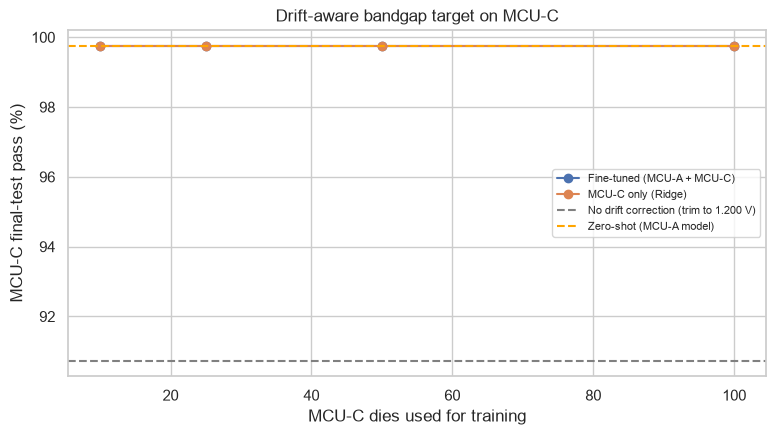

In [13]:
plt.figure(figsize=(9, 4.5))
for a, g in drift[drift["n_MCU-C_dies"] > 0].groupby("approach"):
    plt.plot(g["n_MCU-C_dies"], g["final_pass_%"], marker="o", label=a)
for a in ["No drift correction (trim to 1.200 V)", "Zero-shot (MCU-A model)"]:
    plt.axhline(drift[drift.approach == a]["final_pass_%"].iloc[0], ls="--", label=a, color="grey" if "No" in a else "orange")
plt.xlabel("MCU-C dies used for training"); plt.ylabel("MCU-C final-test pass (%)"); plt.legend(fontsize=8)
plt.title("Drift-aware bandgap target on MCU-C"); plt.show()

# Part 4: Methods ruled out without training

| Method | What it is for | Why not here |
|---|---|---|
| **GAN** (generative adversarial network) | Generating realistic fake data | It can only copy patterns already in the training data, so it adds no new information. Fuse decisions can't rest on fake data (traceability), and the small derivatives already work without it (transfer results in notebooks 01–03) |
| **RNN / LSTM** (recurrent networks) | Sequences: time series, text | Each die is one independent row with no time order, so there is no sequence to learn from |
| **Reinforcement learning** | Learning a sequence of decisions by trial and reward | Trim search: predict-then-verify already needs 1–2 steps. SKU assignment: integer programming finds the **exact** optimum (notebook 04). RL would also need a live tester or simulator to explore, and is hard to certify |
| **Full trained GNN / CNN on wafer maps** | Learning spatial patterns across dies | Tested indirectly in Part 1: if the errors have no spatial structure, these models have nothing to learn |
| **Bigger neural networks** | Complex non-linear patterns | The MLP was tuned in every notebook and never won. The data is small, tabular and near-linear |

# Part 5: Final verdict on every method
Built from the results above, plus notebooks 01 to 04.

In [14]:
def verdict(change_pct, better_is_lower=True, tol=3.0):   # changes under 3% are treated as noise
    gain = -change_pct if better_is_lower else change_pct
    return "helps" if gain > tol else ("hurts" if gain < -tol else "no real effect")

rows = []
for _, r in spatial.iterrows():
    rows.append({"method": "Spatial error check", "task": r.task,
                 "evidence": f"neighbour corr {r.neighbour_corr:+.3f}, wafer share {r['wafer_share_%']:.1f}%",
                 "verdict": "spatial signal" if abs(r.neighbour_corr) > 0.1 else "errors are random"})
for _, r in krig.iterrows():
    rows.append({"method": "Kriging correction", "task": r.task, "evidence": f"MAE {r['change_%']:+.1f}%",
                 "verdict": verdict(r["change_%"])})
for _, r in gnn.iterrows():
    rows.append({"method": "GNN-style neighbour features", "task": r.task, "evidence": f"MAE {r['change_%']:+.1f}%",
                 "verdict": verdict(r["change_%"])})
rows.append({"method": "Confidence routing", "task": "MCU HSI", "evidence": f"iterations {100 * (conf / fixed - 1):+.1f}%",
             "verdict": verdict(100 * (conf / fixed - 1))})
fg = soc_conf.iloc[0]; qrow = soc_conf[soc_conf.method.str.contains("quantile")]
if len(qrow):
    q = qrow.iloc[0]
    ch = 100 * (q["revenue_per_die_$"] / fg["revenue_per_die_$"] - 1)
    rows.append({"method": "Quantile guard band", "task": "SoC binning",
                 "evidence": f"revenue {ch:+.1f}%, unsafe {q['unsafe_%']:.2f}% vs {fg['unsafe_%']:.2f}%",
                 "verdict": verdict(ch, better_is_lower=False) if q["unsafe_%"] <= 0.15 else "unsafe"})
else:
    rows.append({"method": "Quantile guard band", "task": "SoC binning",
                 "evidence": "no quantile level was safe (<= 0.1% unsafe) on validation", "verdict": "does not help"})
gap = (sens_conf["pass_%_error_model_pick"] - sens_conf["pass_%_random_pick"]).iloc[1:].mean()
rows.append({"method": "Confidence routing", "task": "Sensor hybrid flow",
             "evidence": f"pass rate vs random pick {gap:+.1f} points", "verdict": verdict(gap, better_is_lower=False)})
ft = drift[drift.approach.str.startswith("Fine") & (drift["n_MCU-C_dies"] == 50)].iloc[0]
zs = drift[drift.approach.str.startswith("Zero")].iloc[0]
nc = drift[drift.approach.str.startswith("No drift")]["final_pass_%"].iloc[0]
rows.append({"method": "Drift-aware target (zero-shot)", "task": "MCU-C drift",
             "evidence": f"final pass {nc:.1f}% -> {zs['final_pass_%']:.1f}%",
             "verdict": verdict(zs["final_pass_%"] - nc, better_is_lower=False)})
rows.append({"method": "Fine-tuning with 50 MCU-C dies", "task": "MCU-C drift",
             "evidence": f"shift error {zs.MAE_mV:.2f} -> {ft.MAE_mV:.2f} mV; final pass {zs['final_pass_%']:.1f}% -> {ft['final_pass_%']:.1f}%",
             "verdict": verdict(100 * (ft.MAE_mV / zs.MAE_mV - 1)) + " (error only)"})
for meth, ev in [("MLP neural network", "never won in notebooks 01-04"),
                 ("Multi-output model", "worse than separate models (notebook 02)"),
                 ("Isolation Forest", "lost to simple rules (notebooks 02, 03)"),
                 ("ML instead of rules/solver", "lost on OTP checks and memory repair (02, 04)"),
                 ("Integer linear programming", "+34.7% SoC revenue (notebook 04)")]:
    rows.append({"method": meth, "task": "earlier notebooks", "evidence": ev,
                 "verdict": "helps" if "+" in ev else "does not help"})
final = pd.DataFrame(rows)
final

,method,task,evidence,verdict
0,Spatial error check,MCU bandgap code,"neighbour corr +0.038, wafer share 1.3%",errors are random
1,Spatial error check,MCU HSI code,"neighbour corr -0.017, wafer share 0.0%",errors are random
2,Spatial error check,PMIC buck1 code (ref only),"neighbour corr +0.001, wafer share 0.8%",errors are random
3,Spatial error check,Sensor TCO X,"neighbour corr +0.092, wafer share 0.7%",errors are random
4,Spatial error check,SoC 6th-fastest core,"neighbour corr +0.065, wafer share 1.0%",errors are random
5,Kriging correction,MCU bandgap code,MAE +28.7%,hurts
6,Kriging correction,MCU HSI code,MAE +34.0%,hurts
7,Kriging correction,PMIC buck1 code (ref only),MAE +12.2%,hurts
8,Kriging correction,Sensor TCO X,MAE +12.3%,hurts
9,Kriging correction,SoC 6th-fastest core,MAE +12.8%,hurts


# Conclusions

**1. Spatial and graph models (kriging, CNN, GNN): not useful here.**
- After the final models, the errors show **no spatial pattern**: neighbour correlation is +0.00 to +0.09 on all 5 tasks, and the wafer explains only 0–1.3% of the error.
- Kriging-style correction from a 10% sample made every task **worse** (MAE +12% to +34%), because it copies random noise from nearby dies.
- GNN-style neighbour features changed MAE by under 2% either way, which is noise.
- The project brief's spatial idea works only when trim codes are predicted *without* each die's own measurement. Our models use that measurement, so the spatial signal is already captured.

**2. Confidence-based fallback (quantile regression): not useful here.**
- **MCU HSI:** the best setting on validation was "never route". A wasted prediction costs just one measurement, so routing pays off only when the model is almost certainly wrong.
- **SoC:** no quantile level was safe. On validation the lowest unsafe rate was 0.4%, and on test 5.9–11.4% of dies were unsafe. The **fixed guard band from notebook 04 stays**. Note that the fixed guard chosen on validation (60 MHz) was itself slightly unsafe on test (0.33%), which supports notebook 04's more cautious 80 MHz.
- **Sensor:** the error model picked risky dies no better than random (+0.2 points). The calibration error is random noise, and no model can predict it.

**3. Transfer learning and drift-aware targets: helpful. ✅**
- **The real gain is the drift-aware target itself.** Trimming MCU-C to a predicted offset raises final-test pass from **90.7% to 99.8%** on one MCU-C wafer (mean of both wafers 99.4%, notebook 06), even with the MCU-A model as is (zero-shot).
- **Fine-tuning with 50 MCU-C dies** cuts the shift-prediction error from 1.62 to 0.90 mV (−44%). Pass rate is already at its ceiling, but the larger margin matters for production drift.
- **Done:** the drift-aware target is now Part 8 of notebook 01. It was re-checked there with real 2 mV trim steps (same 99.8% on that wafer), and its drift model is saved in `trim_models.joblib`. The sort window must be centred on the offset target.

**4. GAN, RNN/LSTM and reinforcement learning:** ruled out for the reasons in Part 4.

**Overall:** every advanced method suggested in the project brief has now been checked. Only **drift-aware targets with transfer learning** add value beyond notebooks 01 to 04. The final stack:
- simple models: Random Forest for the MCU, Ridge for the PMIC, sensor and SoC
- rules: fuse validation, OTP checks, defect screens
- optimization: SKU assignment, memory repair
- drift-aware targets

## Summary prompt (copy and paste)
```text
Notebook 05 of my AI-Optimized Trim & Fuse project tests advanced methods on the final models of
notebooks 01-04 (MCU bandgap/HSI, PMIC buck1, sensor TCO, SoC core speed), with wafer splits and
settings chosen on validation. Spatial/graph: model errors have no spatial pattern (neighbour corr
<= 0.09, wafer share <= 1.3%); kriging correction worsened MAE by 12-34%; GNN-style neighbour
features changed MAE by < 2%. Confidence fallback (quantile regression): no gain on MCU HSI
(best = never route), unsafe on SoC binning (5.9-11.4% unsafe on test), no better than random for
sensor routing. Drift-aware target on MCU-C: final pass 90.7% -> 99.8% on one wafer (99.4% mean of both); fine-tuning with 50 MCU-C
dies cut shift error 1.62 -> 0.90 mV. GAN, RNN and RL ruled out with reasons. Conclusion: simple
models + rules + optimization + drift-aware targets are the right stack; complex models add nothing.
```